
# Delivery Time Analysis

**Question:** What makes some deliveries take longer, and what could be done to improve delivery performance?

**Data:** Approximately 43,700 delivery orders from February to April 2022, including agent details, store and customer locations, weather, traffic, vehicle type, area, product category and delivery time (in minutes).

**Tools:** Python (Pandas, NumPy, Matplotlib and Seaborn). SQL and Power BI are used in separate project files.


In [1]:
## importing Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/amazon_delivery.csv')
print(df.shape)
df.head()

(43739, 16)


,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         43739 non-null  str    
 1   Agent_Age        43739 non-null  int64  
 2   Agent_Rating     43685 non-null  float64
 3   Store_Latitude   43739 non-null  float64
 4   Store_Longitude  43739 non-null  float64
 5   Drop_Latitude    43739 non-null  float64
 6   Drop_Longitude   43739 non-null  float64
 7   Order_Date       43739 non-null  str    
 8   Order_Time       43739 non-null  str    
 9   Pickup_Time      43739 non-null  str    
 10  Weather          43648 non-null  str    
 11  Traffic          43739 non-null  str    
 12  Vehicle          43739 non-null  str    
 13  Area             43739 non-null  str    
 14  Delivery_Time    43739 non-null  int64  
 15  Category         43739 non-null  str    
dtypes: float64(5), int64(2), str(9)
memory usage: 5.3 MB


In [4]:
df.describe().round(2)

,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Delivery_Time
count,43739.00,43685.00,43739.00,43739.00,43739.00,43739.00,43739.00
mean,29.57,4.63,17.21,70.66,17.46,70.82,124.91
std,5.82,0.33,7.76,21.48,7.34,21.15,51.92
min,15.00,1.00,-30.90,-88.37,0.01,0.01,10.00
25%,25.00,4.50,12.93,73.17,12.99,73.28,90.00
50%,30.00,4.70,18.55,75.90,18.63,76.00,125.00
75%,35.00,4.90,22.73,78.05,22.79,78.10,160.00
max,50.00,6.00,30.91,88.43,31.05,88.56,270.00


In [5]:
# missing values
missing = df.isnull().sum()
print(missing[missing > 0])

Agent_Rating    54
Weather         91
dtype: int64


In [6]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate Order_IDs:', df['Order_ID'].duplicated().sum())

Duplicate rows: 0
Duplicate Order_IDs: 0


In [7]:
# Check categorical column distributions
categorical_cols = ['Weather', 'Traffic', 'Vehicle', 'Area', 'Category']

for col in categorical_cols:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False))


Weather:


Weather
Fog           7440
Stormy        7374
Cloudy        7288
Sandstorms    7245
Windy         7223
Sunny         7078
NaN             91
Name: count, dtype: int64


Traffic:


Traffic
Low        14999
Jam        13725
Medium     10628
High        4296
NaN           91
Name: count, dtype: int64


Vehicle:


Vehicle
motorcycle     25527
scooter        14639
van             3558
bicycle           15
Name: count, dtype: int64


Area:


Area
Metropolitian     32698
Urban              9751
Other              1138
Semi-Urban          152
Name: count, dtype: int64


Category:


Category
Electronics     2849
Books           2824
Jewelry         2802
Toys            2781
Skincare        2772
Snacks          2770
Outdoors        2747
Apparel         2726
Sports          2719
Grocery         2691
Pet Supplies    2690
Home            2685
Cosmetics       2677
Kitchen         2673
Clothing        2667
Shoes           2666
Name: count, dtype: int64

In [8]:
# values that should not be possible
print('Ratings above 5:', (df['Agent_Rating'] > 5).sum())
print('Agents under 18:', (df['Agent_Age'] < 18).sum())
print('Store latitude or longitude = 0:', ((df['Store_Latitude'] == 0) | (df['Store_Longitude'] == 0)).sum())
print('Negative store latitude:', (df['Store_Latitude'] < 0).sum())
print('Dates:', df['Order_Date'].min(), 'to', df['Order_Date'].max())

Ratings above 5: 53
Agents under 18: 38
Store latitude or longitude = 0: 3505
Negative store latitude: 188
Dates: 2022-02-11 to 2022-04-06


**Problems I found**
- Missing values in Agent_Rating (54) and Weather (91). Traffic has the text "NaN " instead of real blanks.
- Extra spaces in the text columns (like "Low ") and a spelling mistake, "Metropolitian".
- 53 ratings above 5 and 38 agents under 18.
- 3,505 stores at coordinates (0, 0) and 188 with a negative latitude.
- The data covers about 8 weeks (11 Feb to 6 Apr 2022).

In [9]:
df_raw = df.copy()  
df = df_raw.copy()

In [10]:
# remove extra spaces from text columns
for col in ['Order_ID', 'Weather', 'Traffic', 'Vehicle', 'Area', 'Category']:
    df[col] = df[col].str.strip()

# "NaN" was stored as text, so make it a real missing value
df['Traffic'] = df['Traffic'].replace(['NaN', 'nan', 'NAN'], np.nan)

# fix spelling
df['Area'] = df['Area'].replace('Metropolitian', 'Metropolitan')

print(df['Traffic'].value_counts(dropna=False).to_dict())
print(df['Area'].value_counts().to_dict())

{'Low': 14999, 'Jam': 13725, 'Medium': 10628, 'High': 4296, nan: 91}
{'Metropolitan': 32698, 'Urban': 9751, 'Other': 1138, 'Semi-Urban': 152}


In [11]:
# before dropping the rows with missing weather/traffic, see what else is wrong with them
bad = df['Weather'].isna() | df['Traffic'].isna()

print('Rows missing weather or traffic:', bad.sum())
print('Ratings above 5 in these rows:', (bad & (df['Agent_Rating'] > 5)).sum(), 'of', (df['Agent_Rating'] > 5).sum())
print('Agents under 18 in these rows:', (bad & (df['Agent_Age'] < 18)).sum(), 'of', (df['Agent_Age'] < 18).sum())
print('Bicycle orders in these rows:', (bad & (df['Vehicle'] == 'bicycle')).sum(), 'of', (df['Vehicle'] == 'bicycle').sum())

df[bad][['Agent_Age', 'Agent_Rating', 'Vehicle']].head()

print('Missing Weather:', df['Weather'].isna().sum())
print('Missing Traffic:', df['Traffic'].isna().sum())
print('Missing both:', (df['Weather'].isna() & df['Traffic'].isna()).sum())

Rows missing weather or traffic: 91
Ratings above 5 in these rows: 53 of 53
Agents under 18 in these rows: 38 of 38
Bicycle orders in these rows: 15 of 15
Missing Weather: 91
Missing Traffic: 91
Missing both: 91


All the impossible ratings, all the under-18 agents and all the bicycle orders are inside these 91 rows, so they look like one group of broken records. I decided to drop them.

In [12]:
df = df.dropna(subset=['Weather', 'Traffic']).reset_index(drop=True)
print(len(df), 'rows left out of', len(df_raw))

43648 rows left out of 43739


In [13]:
# a few ratings are still missing, fill them with the median
print('Missing ratings:', df['Agent_Rating'].isna().sum())
median_rating = df['Agent_Rating'].median()
df['Agent_Rating'] = df['Agent_Rating'].fillna(median_rating)
print('Median used:', median_rating)

Missing ratings: 54
Median used: 4.7


In [14]:
# check again after dropping
print('Age:', df['Agent_Age'].min(), 'to', df['Agent_Age'].max())
print('Rating:', df['Agent_Rating'].min(), 'to', df['Agent_Rating'].max())
print('Vehicles:', list(df['Vehicle'].unique()))

Age: 20 to 39
Rating: 2.5 to 5.0
Vehicles: ['motorcycle', 'scooter', 'van']


In [15]:
# coordinates
zero_store = (df['Store_Latitude'] == 0) | (df['Store_Longitude'] == 0)
print('Stores at (0, 0):', zero_store.sum())

# negative store latitude
neg_lat = df['Store_Latitude'] < 0
print('Negative store latitude:', neg_lat.sum())
df.loc[neg_lat, 'Store_Latitude'] = df.loc[neg_lat, 'Store_Latitude'].abs()

Stores at (0, 0): 3495
Negative store latitude: 156


In [16]:
# (0, 0) is not a real location. I keep these orders but mark them,
# and blank out the coordinates so no wrong distance is calculated
df['valid_location'] = ~zero_store
df.loc[zero_store, ['Store_Latitude', 'Store_Longitude', 'Drop_Latitude', 'Drop_Longitude']] = np.nan
df['valid_location'].value_counts()

valid_location
True     40153
False     3495
Name: count, dtype: int64

In [17]:
# convert dates and times
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Order_Time'] = pd.to_datetime(df['Order_Time'], format='%H:%M:%S').dt.time
df['Pickup_Time'] = pd.to_datetime(df['Pickup_Time'], format='%H:%M:%S').dt.time
df[['Order_Date', 'Order_Time', 'Pickup_Time']].head()

,Order_Date,Order_Time,Pickup_Time
0,2022-03-19,11:30:00,11:45:00
1,2022-03-25,19:45:00,19:50:00
2,2022-03-19,08:30:00,08:45:00
3,2022-04-05,18:00:00,18:10:00
4,2022-03-26,13:30:00,13:45:00


In [18]:
df.info()
print('Still missing:')
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 43648 entries, 0 to 43647
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         43648 non-null  str           
 1   Agent_Age        43648 non-null  int64         
 2   Agent_Rating     43648 non-null  float64       
 3   Store_Latitude   40153 non-null  float64       
 4   Store_Longitude  40153 non-null  float64       
 5   Drop_Latitude    40153 non-null  float64       
 6   Drop_Longitude   40153 non-null  float64       
 7   Order_Date       43648 non-null  datetime64[us]
 8   Order_Time       43648 non-null  object        
 9   Pickup_Time      43648 non-null  object        
 10  Weather          43648 non-null  str           
 11  Traffic          43648 non-null  str           
 12  Vehicle          43648 non-null  str           
 13  Area             43648 non-null  str           
 14  Delivery_Time    43648 non-null  int64         
 

- Removed spaces, fixed "NaN" text and the spelling mistake.
- Dropped 91 broken rows (0.2% of the data).
- Filled 54 missing ratings with the median (4.7).
- Fixed 156 negative store latitudes.
- Marked 3,495 orders with a (0, 0) store as invalid location. I kept them for everything except distance.

In [39]:
# distance between store and customer
R = 6371   # earth radius in km

lat1, lon1, lat2, lon2 = map(np.radians, [df['Store_Latitude'], df['Store_Longitude'],
                                          df['Drop_Latitude'], df['Drop_Longitude']])

a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df['distance_km'] = 2 * R * np.arcsin(np.sqrt(a))

df['distance_km'].describe().round(2)

count    40153.00
mean         9.71
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.63
max         20.97
Name: distance_km, dtype: float64

In [40]:
# time in minutes since midnight
def to_minutes(t):
    return t.hour * 60 + t.minute

df['order_min'] = df['Order_Time'].apply(to_minutes)
df['pickup_min'] = df['Pickup_Time'].apply(to_minutes)

# if pickup is smaller than order, the pickup was after midnight, so add 1440 minutes
df['wait_min'] = np.where(df['pickup_min'] < df['order_min'],
                          df['pickup_min'] + 1440 - df['order_min'],
                          df['pickup_min'] - df['order_min'])

print('Rows that crossed midnight:', (df['pickup_min'] < df['order_min']).sum())
df['wait_min'].describe()

Rows that crossed midnight: 828


count    43648.000000
mean         9.991294
std          4.086680
min          5.000000
25%          5.000000
50%         10.000000
75%         15.000000
max         15.000000
Name: wait_min, dtype: float64

In [41]:
df['order_hour'] = df['Order_Time'].apply(lambda t: t.hour)
df['weekday'] = df['Order_Date'].dt.day_name()

df['order_hour'].value_counts().sort_index()

order_hour
0      429
8     1810
9     1934
10    1980
11    1950
12     888
13     779
14     785
15     871
16     706
17    4247
18    4467
19    4579
20    4504
21    4663
22    4558
23    4498
Name: count, dtype: int64

In [42]:
# late orders: the data has no promised delivery time, so I chose 150 minutes myself
LATE_MIN = 150
df['is_late'] = np.where(df['Delivery_Time'] > LATE_MIN, 1, 0)

print('Late orders (over 150 min):', round(df['is_late'].mean() * 100, 1), '% of all orders')

Late orders (over 150 min): 27.9 % of all orders


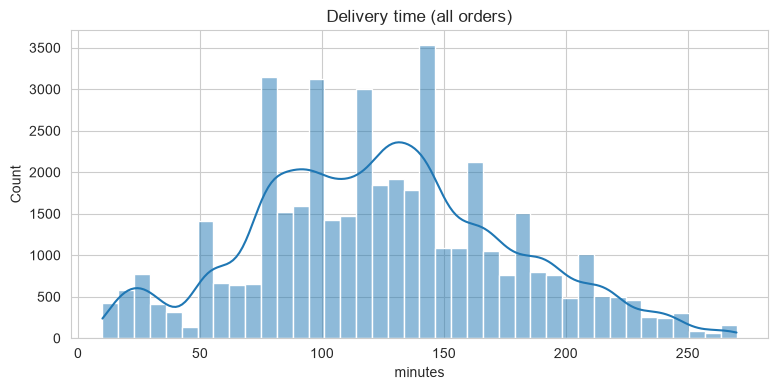

Mean: 124.9 | Median: 125.0


In [43]:
plt.figure(figsize=(9, 4))
sns.histplot(df['Delivery_Time'], bins=40, kde=True)
plt.title('Delivery time (all orders)')
plt.xlabel('minutes')
plt.show()

print('Mean:', round(df['Delivery_Time'].mean(), 1), '| Median:', df['Delivery_Time'].median())

               mean  count
Category                  
Grocery        26.5   2688
Toys          129.4   2773
Clothing      130.5   2662
Jewelry       130.7   2796
Electronics   130.9   2843
Home          131.0   2680
Shoes         131.1   2661
Books         131.1   2817
Outdoors      131.2   2741
Pet Supplies  131.4   2684
Snacks        131.9   2767
Apparel       132.0   2722
Skincare      132.1   2766
Kitchen       132.3   2667
Sports        132.3   2711
Cosmetics     132.9   2670


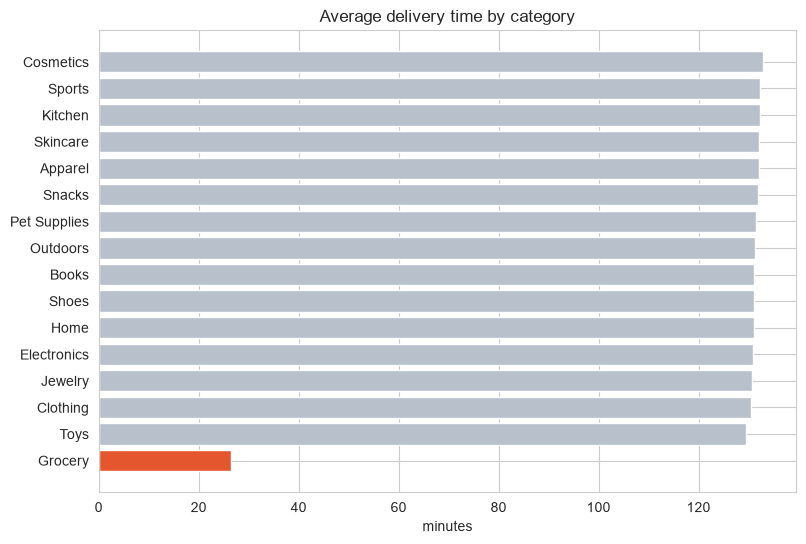

In [44]:
cat_stats = df.groupby('Category')['Delivery_Time'].agg(['mean', 'count']).round(1).sort_values('mean')
print(cat_stats)

# Grocery in red, the rest in grey
colors = ['#E4572E' if c == 'Grocery' else '#B8C0CC' for c in cat_stats.index]

plt.figure(figsize=(9, 6))
plt.barh(cat_stats.index, cat_stats['mean'], color=colors)
plt.title('Average delivery time by category')
plt.xlabel('minutes')
plt.show()

Grocery is very different: about 26 minutes against about 130 for every other category, and the other 15 are almost the same as each other. Since it could hide the other patterns, I will look at everything else without Grocery and treat Grocery as its own finding.

In [45]:
std = df[df['Category'] != 'Grocery'].copy()
print('Other orders:', len(std), '| Grocery orders:', len(df) - len(std))
print('Average time, other orders:', round(std['Delivery_Time'].mean(), 1))

Other orders: 40960 | Grocery orders: 2688
Average time, other orders: 131.4


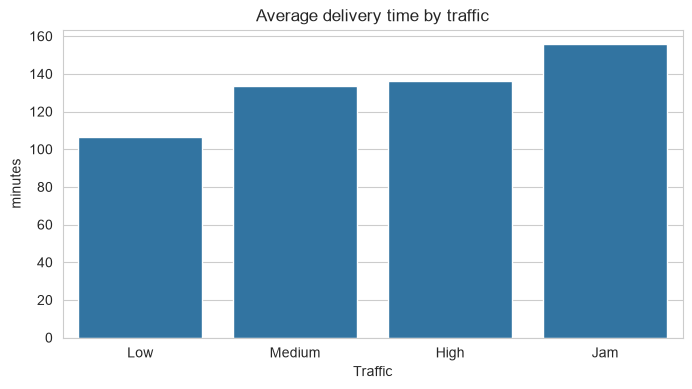

         avg_time  pct_late
Traffic                    
Low         106.5       7.9
Medium      133.4      32.4
High        136.0      33.4
Jam         155.7      50.5


In [46]:
traffic_order = ['Low', 'Medium', 'High', 'Jam']

plt.figure(figsize=(8, 4))
sns.barplot(data=std, x='Traffic', y='Delivery_Time', order=traffic_order, errorbar=None)
plt.title('Average delivery time by traffic')
plt.ylabel('minutes')
plt.show()

# share of orders that are late in each traffic level
traffic_summary = std.groupby('Traffic')[['Delivery_Time', 'is_late']].mean().loc[traffic_order]
traffic_summary.columns = ['avg_time', 'pct_late']
traffic_summary['pct_late'] = traffic_summary['pct_late'] * 100
print(traffic_summary.round(1))

In [48]:
# is the difference between traffic levels real, or just chance? 
from scipy import stats

groups = [std.loc[std['Traffic'] == t, 'Delivery_Time'] for t in traffic_order]
f_stat, p_value = stats.f_oneway(*groups)

print('F =', round(f_stat, 1))
print('p-value:', '< 0.001' if p_value < 0.001 else round(p_value, 3))
print()
print(std.groupby('Traffic')['Delivery_Time'].mean().loc[traffic_order].round(1))

F = 3073.6
p-value: < 0.001

Traffic
Low       106.5
Medium    133.4
High      136.0
Jam       155.7
Name: Delivery_Time, dtype: float64


**ANOVA in plain words**
- Question: is the average delivery time the same in all four traffic levels? (This is the null hypothesis.)
- The p-value is below 0.001, so the averages are not all equal. At least one traffic level is different. ANOVA does not say which one.
- With about 41,000 orders, even a small gap gives a tiny p-value, so I also look at the averages. Low is about 107 minutes and Jam about 156, which is a big gap in real terms. Medium and High are only about 3 minutes apart.
- This shows a link between traffic and delivery time, not proof that traffic causes the delay.

**Traffic and time of day**
Before I say anything about the order hour, I checked which traffic levels happen at which hours.

In [49]:
std['time_of_day'] = pd.cut(std['order_hour'].replace(0, 24), [7, 11, 16, 24],
                            labels=['Morning 8-11', 'Midday 12-16', 'Evening/night 17-24'])

print(pd.crosstab(std['time_of_day'], std['Traffic']))
print()
print(std.groupby(['time_of_day', 'Traffic'], observed=True)['Delivery_Time'].mean().round(1))

Traffic              High    Jam   Low  Medium
time_of_day                                   
Morning 8-11         1650      0  5557       0
Midday 12-16         2385      0     0    1404
Evening/night 17-24     0  12849  8545    8570

time_of_day          Traffic
Morning 8-11         High       135.6
                     Low         97.6
Midday 12-16         High       136.3
                     Medium     114.4
Evening/night 17-24  Jam        155.7
                     Low        112.2
                     Medium     136.5
Name: Delivery_Time, dtype: float64


Traffic is not spread evenly over the day. Jam only happens in the evening and night, and the morning only has Low and High traffic. So the order hour and the traffic effect are mixed together.

The fairest check is Low traffic, because it exists in both the morning and the evening: about 98 minutes in the morning and about 112 in the evening. So the evening is a bit slower even without traffic, but most of the gap between morning and evening seems to come from traffic and not from the hour itself.

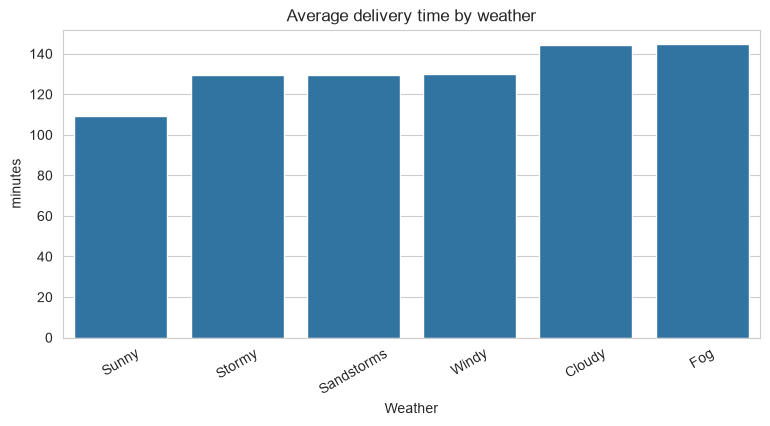

In [50]:
weather_order = std.groupby('Weather')['Delivery_Time'].mean().sort_values().index

plt.figure(figsize=(9, 4))
sns.barplot(data=std, x='Weather', y='Delivery_Time', order=weather_order, errorbar=None)
plt.title('Average delivery time by weather')
plt.ylabel('minutes')
plt.xticks(rotation=30)
plt.show()

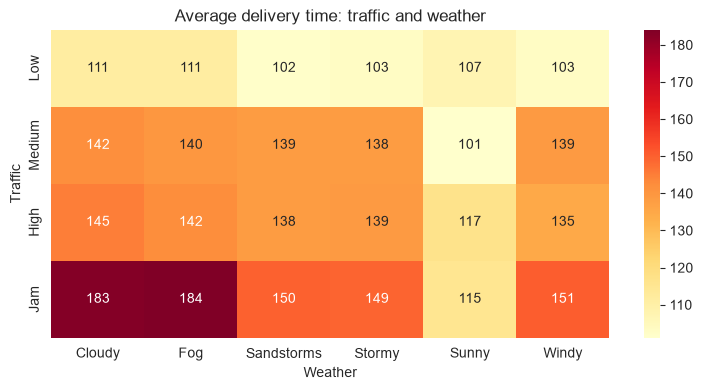

In [51]:
pivot = std.pivot_table(index='Traffic', columns='Weather', values='Delivery_Time', aggfunc='mean')
pivot = pivot.loc[traffic_order]

plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average delivery time: traffic and weather')
plt.show()

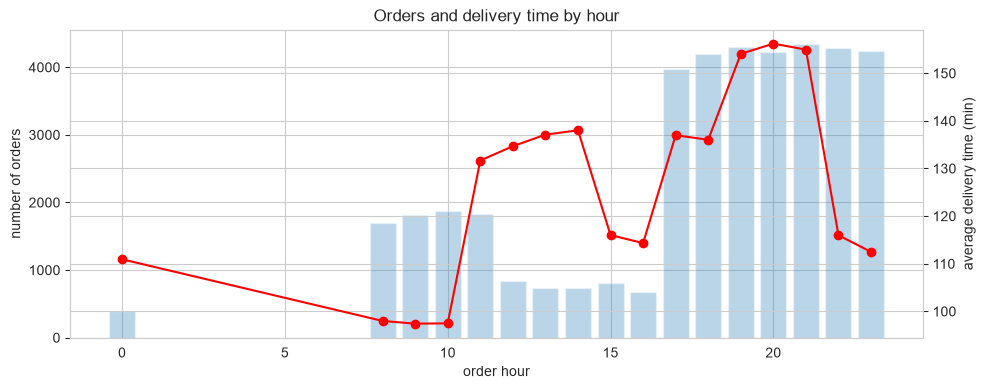

In [52]:
hourly_time = std.groupby('order_hour')['Delivery_Time'].mean()
hourly_orders = std.groupby('order_hour').size()

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(hourly_orders.index, hourly_orders.values, alpha=0.3)
ax1.set_xlabel('order hour')
ax1.set_ylabel('number of orders')

ax2 = ax1.twinx()
ax2.plot(hourly_time.index, hourly_time.values, marker='o', color='red')
ax2.set_ylabel('average delivery time (min)')

plt.title('Orders and delivery time by hour')
plt.show()

               mean  count
Area                      
Metropolitan  136.5  30610
Other         110.3   1061
Semi-Urban    249.2    144
Urban         114.9   9145


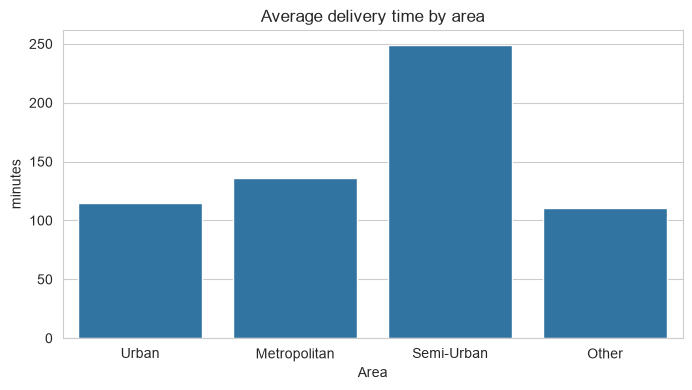

In [53]:
print(std.groupby('Area')['Delivery_Time'].agg(['mean', 'count']).round(1))

plt.figure(figsize=(8, 4))
sns.barplot(data=std, x='Area', y='Delivery_Time', errorbar=None)
plt.title('Average delivery time by area')
plt.ylabel('minutes')
plt.show()

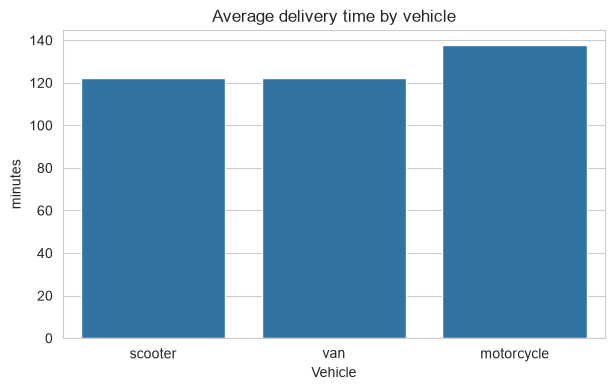

In [54]:
vehicle_order = std.groupby('Vehicle')['Delivery_Time'].mean().sort_values().index

plt.figure(figsize=(7, 4))
sns.barplot(data=std, x='Vehicle', y='Delivery_Time', order=vehicle_order, errorbar=None)
plt.title('Average delivery time by vehicle')
plt.ylabel('minutes')
plt.show()

                mean  count
distance_band              
0-5 km         111.0  10154
5-10 km        121.8  10147
10-15 km       149.0  10169
15-25 km       149.3   7229


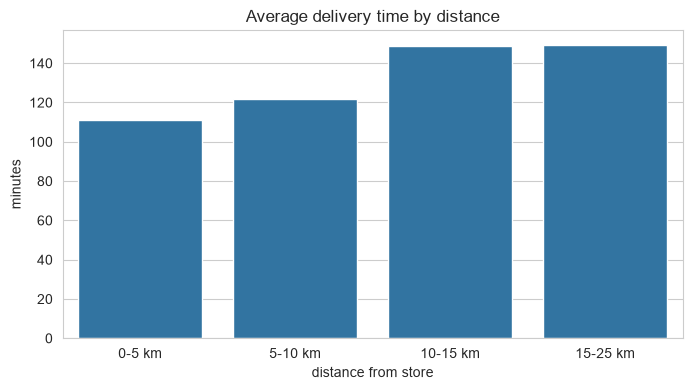

In [55]:
valid = std[std['valid_location']].copy()
valid['distance_band'] = pd.cut(valid['distance_km'], [0, 5, 10, 15, 25],
                                labels=['0-5 km', '5-10 km', '10-15 km', '15-25 km'])

print(valid.groupby('distance_band', observed=True)['Delivery_Time'].agg(['mean', 'count']).round(1))

plt.figure(figsize=(8, 4))
sns.barplot(data=valid, x='distance_band', y='Delivery_Time', errorbar=None)
plt.title('Average delivery time by distance')
plt.xlabel('distance from store')
plt.ylabel('minutes')
plt.show()

              mean  count
rating_band              
4.0 or less  180.4   2229
4.1-4.5      152.8   8394
4.6-4.7      121.8  13289
4.8-4.9      120.3  13313
5.0          127.6   3735


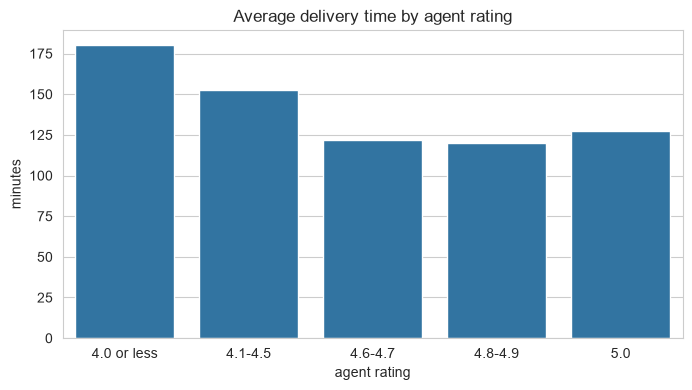

In [56]:
std['rating_band'] = pd.cut(std['Agent_Rating'], [0, 4.0, 4.5, 4.7, 4.9, 5.0],
                            labels=['4.0 or less', '4.1-4.5', '4.6-4.7', '4.8-4.9', '5.0'])

print(std.groupby('rating_band', observed=True)['Delivery_Time'].agg(['mean', 'count']).round(1))

plt.figure(figsize=(8, 4))
sns.barplot(data=std, x='rating_band', y='Delivery_Time', errorbar=None)
plt.title('Average delivery time by agent rating')
plt.xlabel('agent rating')
plt.ylabel('minutes')
plt.show()

In [57]:
# do low rated agents also get longer trips?
valid['rating_group'] = pd.cut(valid['Agent_Rating'], [0, 4.0, 4.5, 5.0],
                               labels=['4.0 or less', '4.1-4.5', 'above 4.5'])
print(valid.groupby('rating_group', observed=True)[['distance_km', 'Delivery_Time']].mean().round(1))

              distance_km  Delivery_Time
rating_group                            
4.0 or less          12.2          180.5
4.1-4.5               9.9          152.8
above 4.5             9.5          121.9


In [58]:
# smaller factors, tables only
std['age_group'] = pd.cut(std['Agent_Age'], [0, 25, 30, 35, 40], labels=['20-25', '26-30', '31-35', '36-39'])
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

print(std.groupby('Vehicle')['Delivery_Time'].agg(['mean', 'count']).round(1))
print()
print(std.groupby('age_group', observed=True)['Delivery_Time'].agg(['mean', 'count']).round(1))
print()
print(std.groupby('weekday')['Delivery_Time'].mean().round(1).loc[weekday_order])
print()
print('Correlation between prep wait time and delivery time:',
      round(std['wait_min'].corr(std['Delivery_Time']), 2))

             mean  count
Vehicle                 
motorcycle  137.8  23936
scooter     122.3  13722
van         122.3   3302

            mean  count
age_group              
20-25      114.8  12160
26-30      121.4  10212
31-35      148.2  10276
36-39      147.0   8312

weekday
Monday       131.2
Tuesday      126.7
Wednesday    138.8
Thursday     125.8
Friday       133.8
Saturday     130.5
Sunday       131.6
Name: Delivery_Time, dtype: float64

Correlation between prep wait time and delivery time: -0.01


## 5. What I found

(These are for the orders without Grocery, about 41,000 orders, average 131 minutes.)

1. **Grocery is a separate fast service.** About 26 minutes against about 131 for the rest. Product category does not matter for the other 15 categories (129 to 133 minutes).
2. **Order hour and traffic show the biggest differences.** Orders placed between 8 and 10 take about 97 minutes, while orders between 19 and 21 take about 155 minutes. Low traffic averages about 107 minutes and Jam about 156. These two are mixed together, because Jam only happens in the evening and night (see the table above).
3. **Traffic.** About 8% of orders are late (over 150 minutes) in Low traffic, against about 51% in Jam. Medium and High traffic look almost the same (133 and 136 minutes). A one-way ANOVA confirms that the traffic levels do not all have the same average (p < 0.001).
4. **Weather.** Sunny is about 109 minutes and Cloudy or Fog about 145. The worst case is Jam with Cloudy or Fog (about 183 minutes). Sunny stays fast (101 to 117 minutes) even in heavy traffic.
5. **Agent rating.** Agents rated 4.0 or less average about 180 minutes, 4.1 to 4.5 about 153, and 4.6 and above about 120 to 128. This could go both ways: slow deliveries may also lower a rating. Agents rated 4.0 or less also get longer trips (about 12 km against 9.5 km), so distance explains some of it, but I cannot say how much.
6. **Distance.** About 111 minutes for 0 to 5 km, 122 for 5 to 10 km, then about 149 for anything over 10 km.
7. **Agent age.** Agents aged 30 or under average about 115 to 121 minutes and older agents about 147. I would not read much into this, since age may be linked to other things like area or vehicle.
8. **Area and vehicle.** Metropolitan (about 137 min) is slower than Urban (about 115 min), and motorcycles (about 138 min) are slower than scooters and vans (about 122 min). Semi-Urban looks very slow but has only 144 orders, so I ignore it.
9. **No real effect:** day of the week and the order-to-pickup wait time.

## 6. What could be done
- Add more agents between 19:00 and 21:00 (part of this is the evening traffic, so traffic needs to be looked at too). Orders at 22:00 to 23:00 are about as many but much faster (about 112 to 116 minutes), which is worth looking into.
- Show longer delivery estimates in Jam traffic and bad weather (Cloudy or Fog).
- Give extra support to agents rated 4.0 or less, and avoid giving them the longest-distance orders.
- Look at deliveries over 10 km, where delivery time jumps.
- Find out why Grocery is so fast and whether it can be copied for other categories.

## 7. Limits of this analysis
- Only about 8 weeks of data, so I cannot say anything about seasons.
- It shows links between things, not proof of cause.
- About 8% of orders have no valid location, so they are left out of the distance analysis.
- Bicycle orders were removed with the broken rows, so they are not analysed.
- Semi-Urban has too few orders to trust.
- An average delivery time of about 2 hours and the Grocery pattern make me think the data may be partly made up, so it may not match real operations.
- "Late" here means over 150 minutes (about 30% of the orders without Grocery). I picked 150 myself, because the data has no promised delivery time, so it is not late against a real promise.
- Traffic and time of day are mixed together (Jam only happens in the evening and night), so I cannot fully separate the two effects.
- Distance is a straight line, not the real road distance.

## 8. Save the cleaned data

In [59]:
final_cols = ['Order_ID', 'Agent_Age', 'Agent_Rating', 'Order_Date', 'Order_Time', 'Pickup_Time',
              'Weather', 'Traffic', 'Vehicle', 'Area', 'Category', 'Delivery_Time',
              'distance_km', 'wait_min', 'order_hour', 'weekday', 'is_late', 'valid_location']

df[final_cols].to_csv('../data/amazon_delivery_clean.csv', index=False)
print(df[final_cols].shape)

(43648, 18)
